<a href="https://colab.research.google.com/github/Danylo5051/machine-learning-practice/blob/main/%D0%A1%D0%B0%D1%82%D0%BA%D0%BE%D0%94_4%D0%BA_9%D0%B3_%D0%9B%D0%A05_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D1%96_%D1%80%D1%8F%D0%B4%D0%B8_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [28]:
# Імпортуйте необхідні бібліотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [29]:
# Завантажте датасет з Kaggle
df = pd.read_csv('kaggel_weather_2013_to_2024.csv')

In [30]:
# Зчитайте датасет у DataFrame та перегляньте дані
print("Перші 5 рядків:")
display(df.head())

print("\nІнформація про структуру датасета:")
df.info()

print("\nОписова статистика:")
display(df.describe())

Перші 5 рядків:


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



Інформація про структуру датасета:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions          

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,1778.000000,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


Підготовка даних

In [31]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
df['DATE'] = pd.to_datetime(df['DATE'])

df = df.sort_values(by='DATE')

df = df.drop(columns=['Unnamed: 0'])

df.set_index('DATE', inplace=True)

In [32]:
# Перегляньте інформацію про структуру датасету
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  month                  3557 non-null  

In [33]:
# Перевірте наявність пропущених значень
display(df.isnull().sum())

,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0
precipcover,0


Графік температури

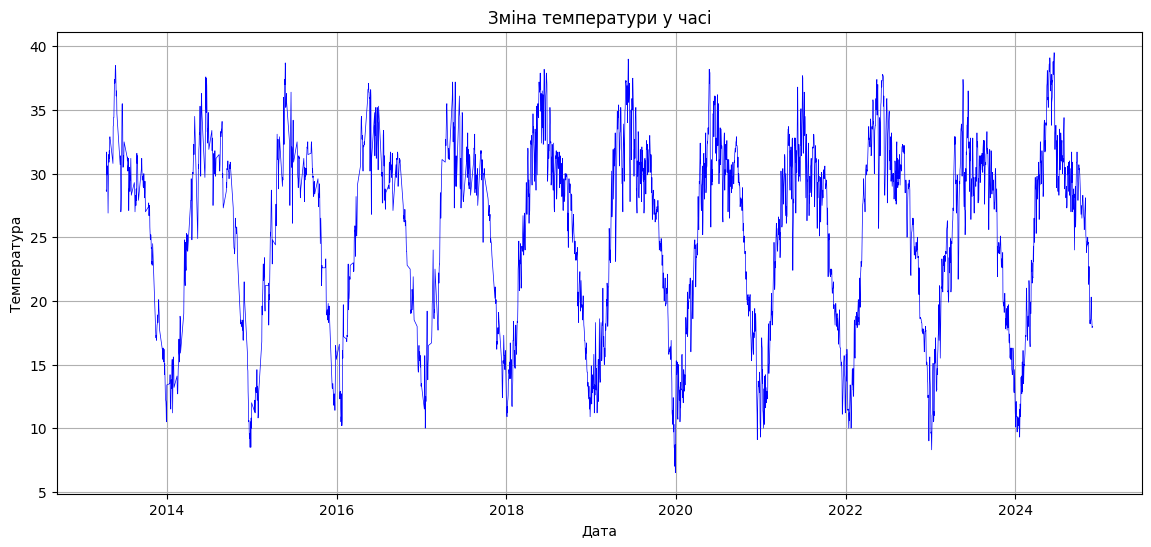

In [34]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(14, 6))
plt.plot(df.index, df['temp'], color='blue', linewidth=0.5)
plt.title('Зміна температури у часі')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.grid(True)
plt.show()

Ковзне середнє

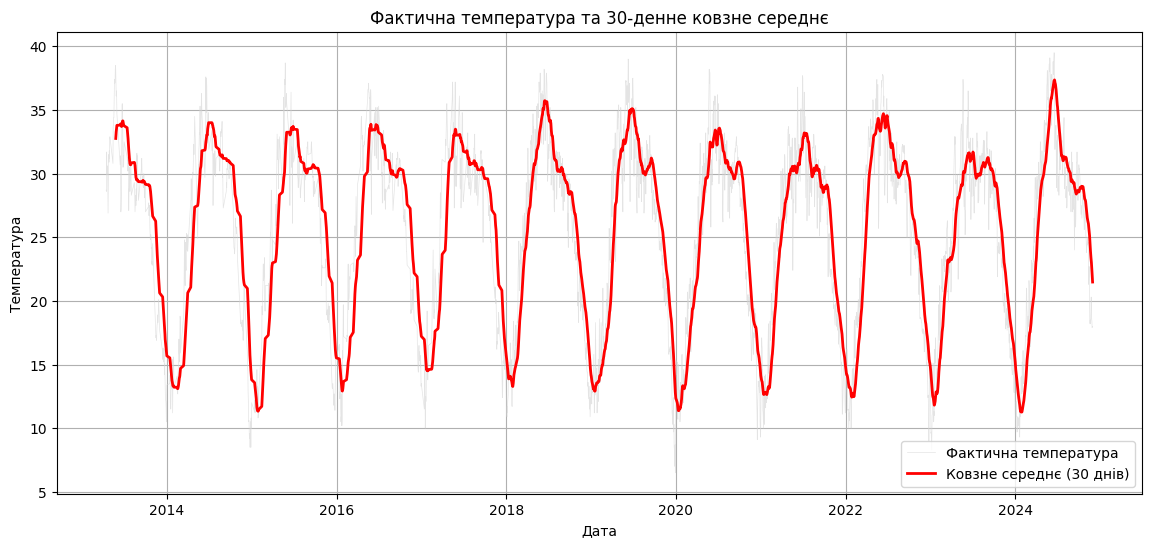

In [35]:
# Обчисліть та візуалізуйте ковзне середнє температури
plt.figure(figsize=(14, 6))

rolling_mean = df['temp'].rolling(window=30).mean()

plt.plot(df.index, df['temp'], color='lightgray', label='Фактична температура', alpha=0.6, linewidth=0.5)
plt.plot(df.index, rolling_mean, color='red', label='Ковзне середнє (30 днів)', linewidth=2)
plt.title('Фактична температура та 30-денне ковзне середнє')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True)
plt.show()

Розподіл температури

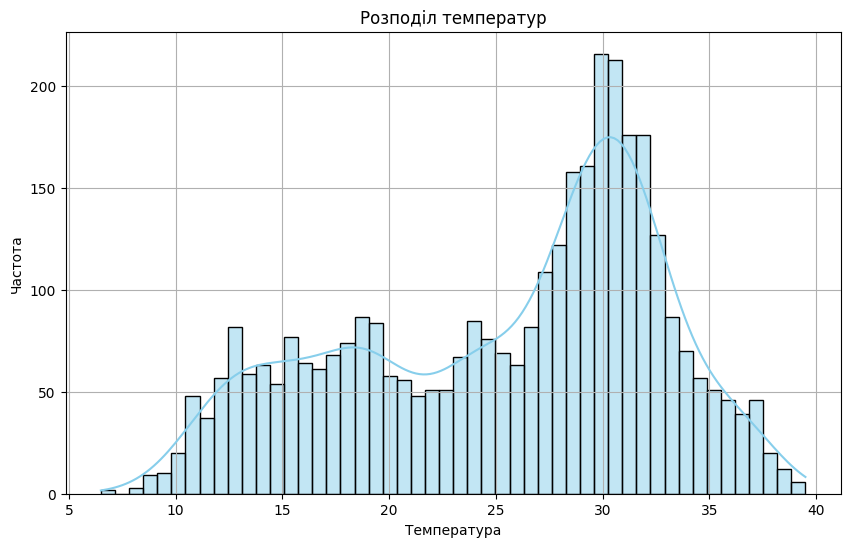

In [36]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(10, 6))
sns.histplot(df['temp'].dropna(), bins=50, kde=True, color='skyblue')
plt.title('Розподіл температур')
plt.xlabel('Температура')
plt.ylabel('Частота')
plt.grid(True)
plt.show()

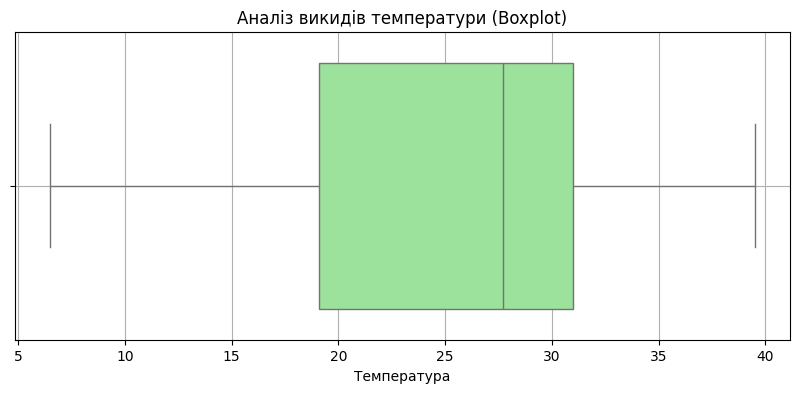

In [37]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['temp'], color='lightgreen')
plt.title('Аналіз викидів температури (Boxplot)')
plt.xlabel('Температура')
plt.grid(True)
plt.show()

Аналіз автокореляції
ACF

PACF

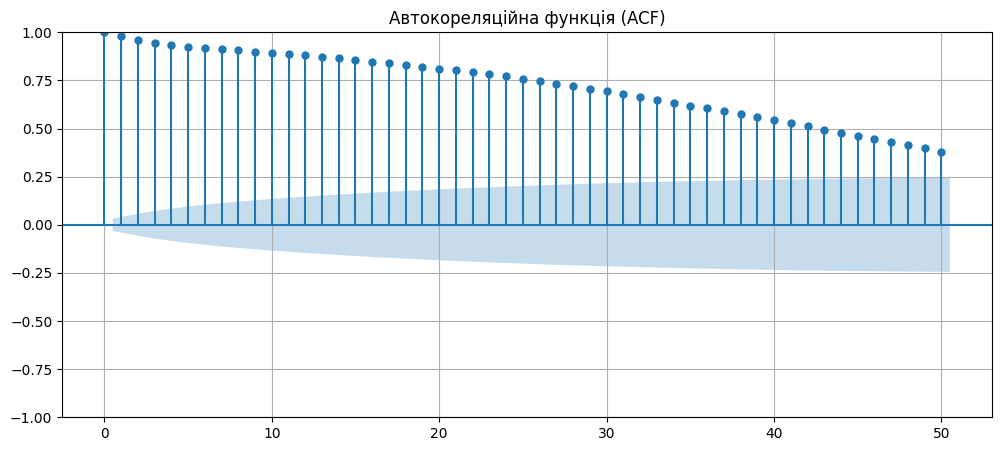

In [38]:
# Побудуйте графік автокореляційної функції (ACF)
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plot_acf(df['temp'].dropna(), lags=50, ax=plt.gca())
plt.title('Автокореляційна функція (ACF)')
plt.grid(True)
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

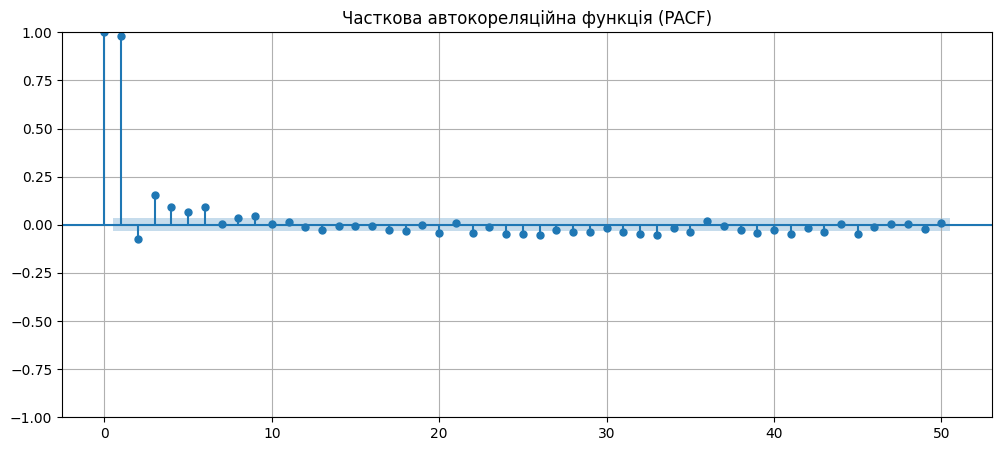

In [39]:
# Побудуйте графік часткової автокореляційної функції (PACF)
from statsmodels.graphics.tsaplots import plot_pacf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plot_pacf(df['temp'].dropna(), lags=50, ax=plt.gca(), method='ywm')
plt.title('Часткова автокореляційна функція (PACF)')
plt.grid(True)
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [40]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
target_series = df['temp'].dropna()

train_size = int(len(target_series) * 0.8)

train_data = target_series.iloc[:train_size]
test_data = target_series.iloc[train_size:]

ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [41]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
from statsmodels.tsa.arima.model import ARIMA
import pandas as pd

arima_model = ARIMA(train_data.values, order=(1, 1, 1))
arima_result = arima_model.fit()

arima_pred_values = arima_result.forecast(steps=len(test_data))

arima_pred = pd.Series(arima_pred_values, index=test_data.index)

In [42]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2845
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -5037.762
Date:                Thu, 15 Oct 2026   AIC                          10081.523
Time:                        07:44:35   BIC                          10099.382
Sample:                             0   HQIC                         10087.964
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3664      0.118     -3.108      0.002      -0.598      -0.135
ma.L1          0.4676      0.112      4.165      0.000       0.248       0.688
sigma2         2.0235      0.034     58.810      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

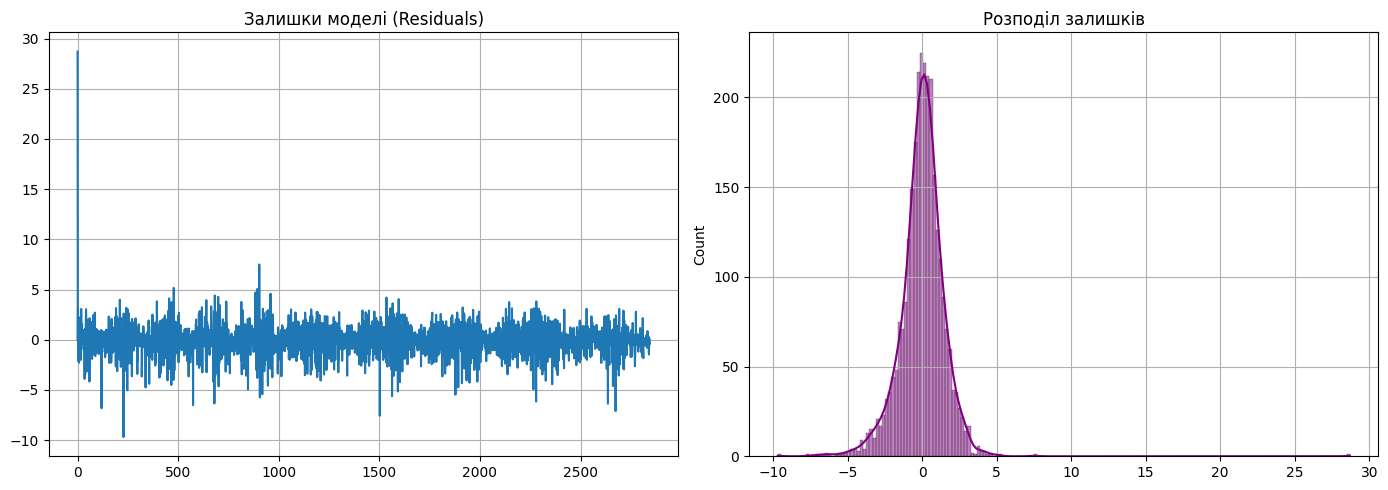

In [43]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = arima_result.resid

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(residuals)
plt.title('Залишки моделі (Residuals)')
plt.grid(True)

plt.subplot(1, 2, 2)
sns.histplot(residuals, kde=True, color='purple')
plt.title('Розподіл залишків')
plt.grid(True)

plt.tight_layout()
plt.show()

In [44]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def mean_absolute_percentage_error(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

mae_arima = mean_absolute_error(test_data, arima_pred)
rmse_arima = np.sqrt(mean_squared_error(test_data, arima_pred))
mape_arima = mean_absolute_percentage_error(test_data, arima_pred)

print(f"ARIMA MAE: {mae_arima:.4f}")
print(f"ARIMA RMSE: {rmse_arima:.4f}")
print(f"ARIMA MAPE: {mape_arima:.4f}%")

ARIMA MAE: 11.2999
ARIMA RMSE: 12.9022
ARIMA MAPE: 40.7747%


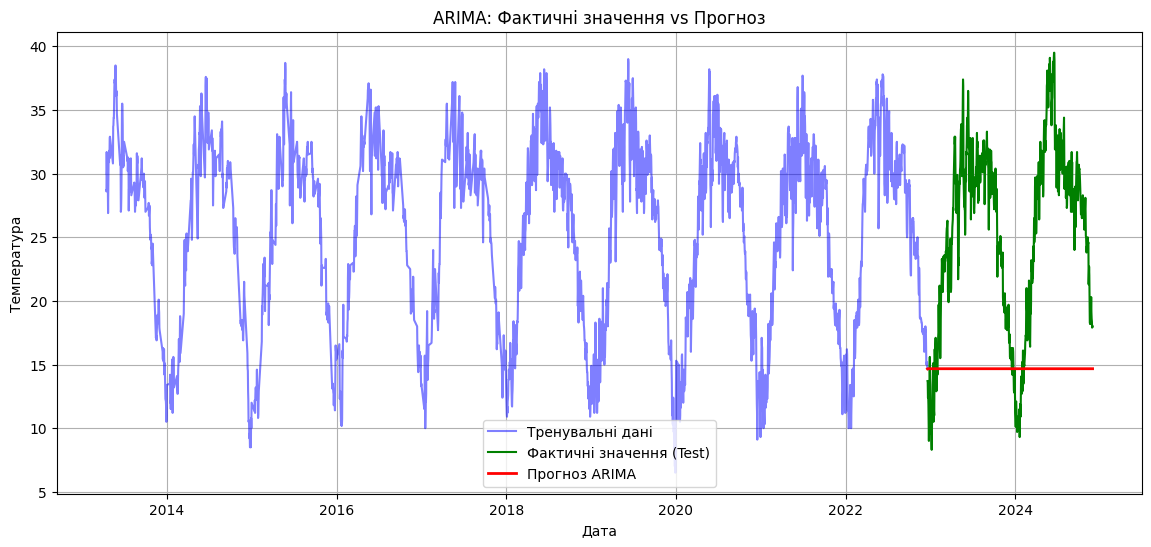

In [45]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 6))

plt.plot(train_data.index, train_data, label='Тренувальні дані', color='blue', alpha=0.5)
plt.plot(test_data.index, test_data, label='Фактичні значення (Test)', color='green')
plt.plot(test_data.index, arima_pred, label='Прогноз ARIMA', color='red', linewidth=2)

plt.title('ARIMA: Фактичні значення vs Прогноз')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True)
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [46]:
# Підготуйте дані у форматі, необхідному для Prophet
prophet_train = pd.DataFrame({
    'ds': train_data.index,
    'y': train_data.values
})

prophet_test = pd.DataFrame({
    'ds': test_data.index,
    'y': test_data.values
})

In [47]:
# Створіть та навчіть модель Prophet
from prophet import Prophet

prophet_model = Prophet(daily_seasonality=True)

prophet_model.fit(prophet_train)

Прогноз

In [48]:
# Побудуйте прогноз Prophet для тестового періоду
prophet_pred = prophet_model.predict(prophet_test[['ds']])

In [62]:
# Обчисліть MAE, RMSE, MAPE для Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_pred_prophet = prophet_pred['yhat'].values
y_true_prophet = prophet_test['y'].values

mae_prophet = mean_absolute_error(y_true_prophet, y_pred_prophet)
rmse_prophet = np.sqrt(mean_squared_error(y_true_prophet, y_pred_prophet))
mape_prophet = np.mean(np.abs((y_true_prophet - y_pred_prophet) / y_true_prophet)) * 100

print(f"Prophet MAE: {mae_prophet:.4f}")
print(f"Prophet RMSE: {rmse_prophet:.4f}")
print(f"Prophet MAPE: {mape_prophet:.4f}%")

Prophet MAE: 2.0047
Prophet RMSE: 2.5904
Prophet MAPE: 9.0282%


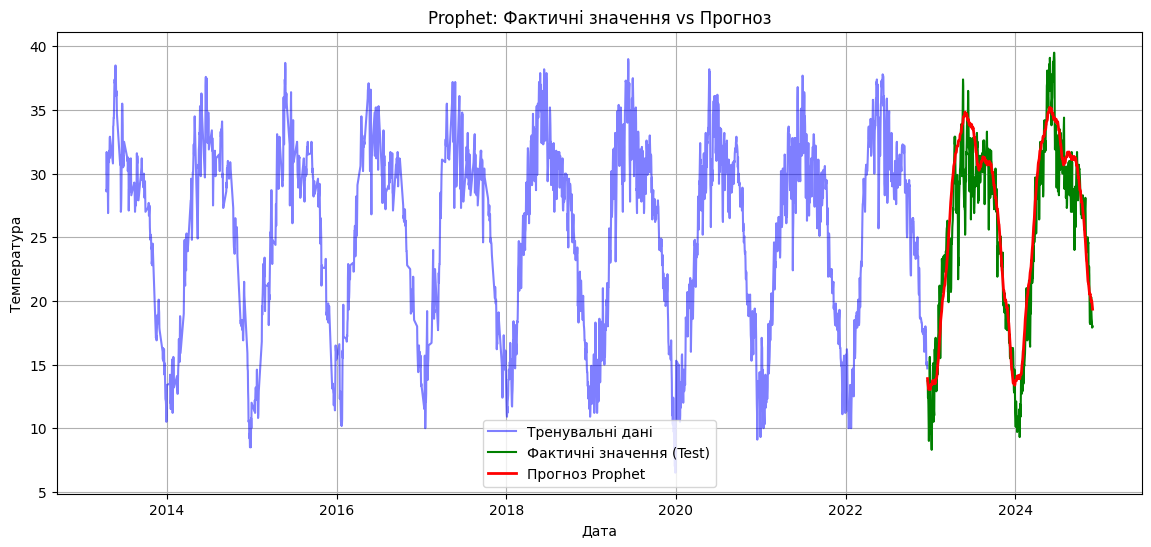

In [63]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 6))

plt.plot(prophet_train['ds'], prophet_train['y'], label='Тренувальні дані', color='blue', alpha=0.5)
plt.plot(prophet_test['ds'], prophet_test['y'], label='Фактичні значення (Test)', color='green')
plt.plot(prophet_test['ds'], prophet_pred['yhat'], label='Прогноз Prophet', color='red', linewidth=2)

plt.title('Prophet: Фактичні значення vs Прогноз')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True)
plt.show()

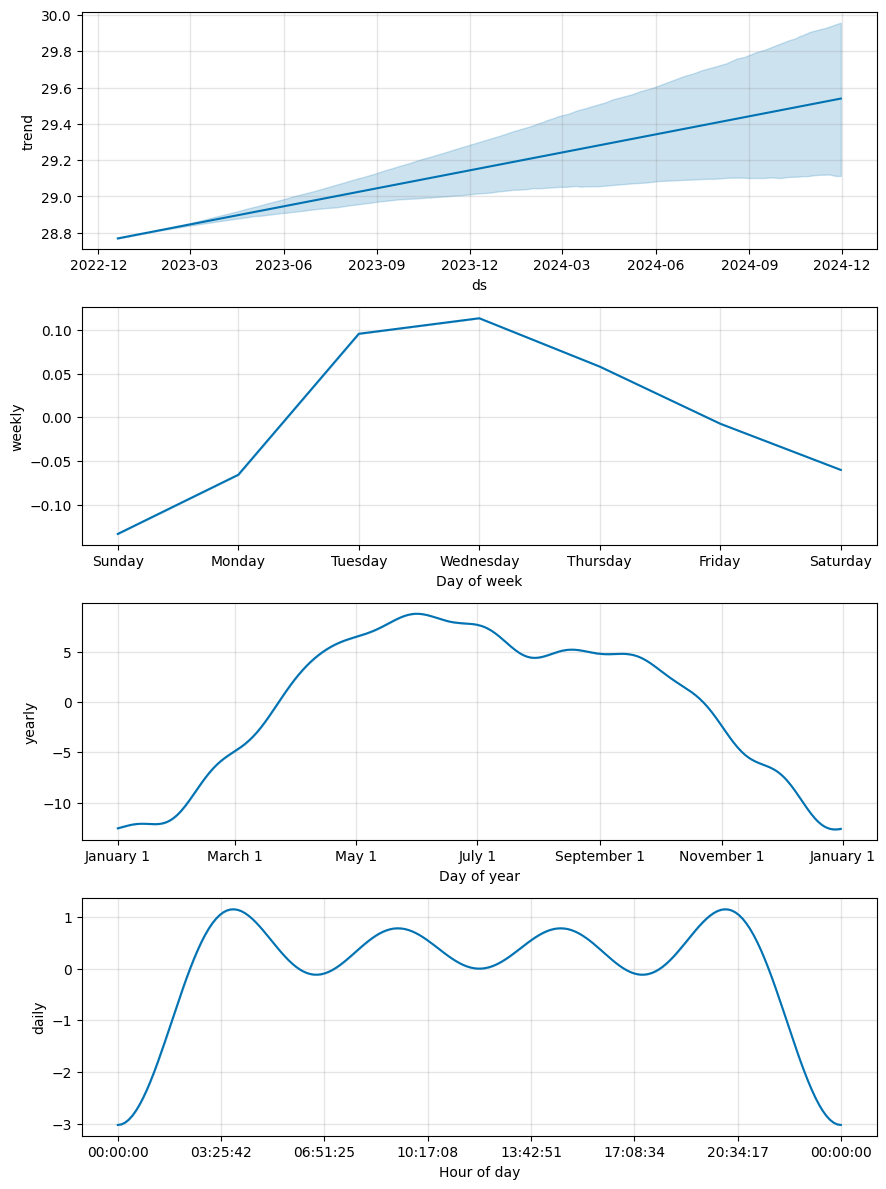

In [64]:
# Побудуйте компоненти моделі Prophet
fig_comp = prophet_model.plot_components(prophet_pred)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [65]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
from sklearn.preprocessing import MinMaxScaler

dataset = target_series.values.reshape(-1, 1)

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(dataset)

def create_dataset(data, look_back=30):
    X, Y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i:(i + look_back), 0])
        Y.append(data[i + look_back, 0])
    return np.array(X), np.array(Y)

look_back = 30
X, y = create_dataset(scaled_data, look_back)

X = np.reshape(X, (X.shape[0], X.shape[1], 1))

In [66]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
train_size_lstm = int(len(X) * 0.8)

X_train, X_test = X[:train_size_lstm], X[train_size_lstm:]
y_train, y_test = y[:train_size_lstm], y[train_size_lstm:]

In [68]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

lstm_model = Sequential()
# Додаємо LSTM шар на 50 нейронів
lstm_model.add(LSTM(units=50, return_sequences=False, input_shape=(X_train.shape[1], 1)))
# Додаємо вихідний шар
lstm_model.add(Dense(units=1))

# Компілюємо модель
lstm_model.compile(optimizer='adam', loss='mean_squared_error')

In [69]:
# Навчіть LSTM-модель
history = lstm_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_test, y_test),
    shuffle=False,
    verbose=1
)

Epoch 1/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0399 - val_loss: 0.0049
Epoch 2/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0056 - val_loss: 0.0041
Epoch 3/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0050 - val_loss: 0.0042
Epoch 4/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0047 - val_loss: 0.0045
Epoch 5/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0045 - val_loss: 0.0043
Epoch 6/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0043 - val_loss: 0.0040
Epoch 7/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0041 - val_loss: 0.0037
Epoch 8/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0040 - val_loss: 0.0035
Epoch 9/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0038 - val_loss: 0.0033
Epoch 10/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0037 - val_loss: 0.0031
Epoch 11/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0036 - val_loss: 0.0030
Epoch 12/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0034 - val_l

In [70]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,355 (122.48 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 20,904 (81.66 KB)

In [71]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
lstm_predictions = lstm_model.predict(X_test)

lstm_predictions_inv = scaler.inverse_transform(lstm_predictions)

y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1))

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [72]:
# Сформуйте часові мітки для тестового прогнозу LSTM
test_timestamps = target_series.index[look_back + train_size_lstm:]

In [73]:
# Обчисліть MAE, RMSE, MAPE для LSTM
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_lstm = mean_absolute_error(y_test_inv, lstm_predictions_inv)
rmse_lstm = np.sqrt(mean_squared_error(y_test_inv, lstm_predictions_inv))
mape_lstm = np.mean(np.abs((y_test_inv - lstm_predictions_inv) / y_test_inv)) * 100

print(f"LSTM MAE: {mae_lstm:.4f}")
print(f"LSTM RMSE: {rmse_lstm:.4f}")
print(f"LSTM MAPE: {mape_lstm:.4f}%")

LSTM MAE: 1.2544
LSTM RMSE: 1.5789
LSTM MAPE: 5.2401%


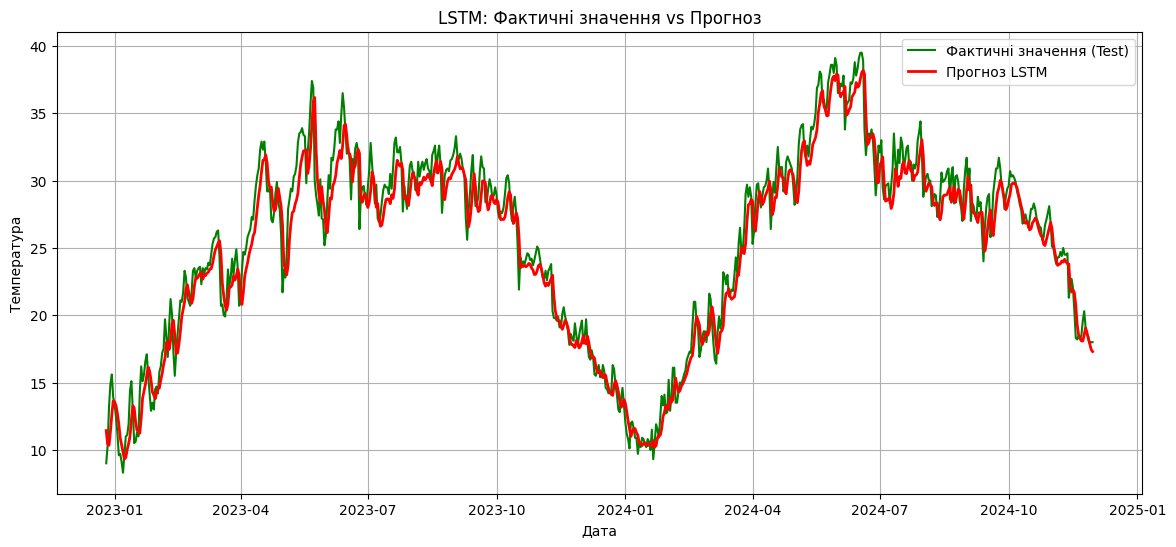

In [74]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 6))

plt.plot(test_timestamps, y_test_inv, label='Фактичні значення (Test)', color='green')
plt.plot(test_timestamps, lstm_predictions_inv, label='Прогноз LSTM', color='red', linewidth=2)

plt.title('LSTM: Фактичні значення vs Прогноз')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True)
plt.show()

Порівняння моделей

Підсумкова таблиця порівняння моделей:


,Модель,MAE,RMSE,MAPE (%)
0,ARIMA,11.299921,12.902242,40.774749
1,Prophet,2.004702,2.590394,9.028200
2,LSTM,1.254393,1.578902,5.240050



Висновок:
Найкращі результати прогнозування показала модель LSTM, оскільки вона має найнижчу відносну похибку MAPE (5.24%).



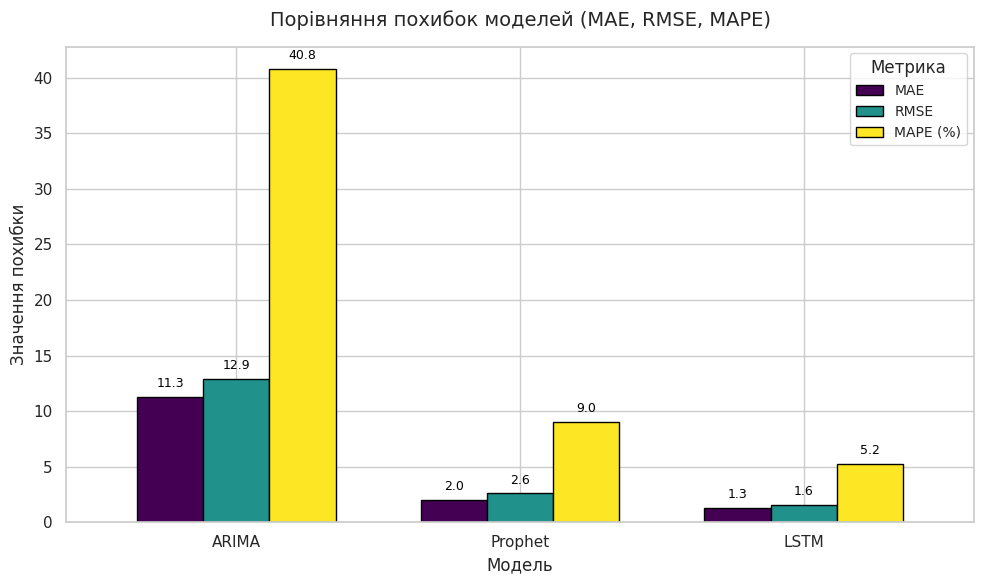

In [77]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
results_data = {
    'Модель': ['ARIMA', 'Prophet', 'LSTM'],
    'MAE': [mae_arima, mae_prophet, mae_lstm],
    'RMSE': [rmse_arima, rmse_prophet, rmse_lstm],
    'MAPE (%)': [mape_arima, mape_prophet, mape_lstm]
}

comparison_df = pd.DataFrame(results_data)

print("Підсумкова таблиця порівняння моделей:")
display(comparison_df)

best_model_idx = comparison_df['MAPE (%)'].idxmin()
best_model_name = comparison_df.loc[best_model_idx, 'Модель']
best_model_mape = comparison_df.loc[best_model_idx, 'MAPE (%)']

print(f"\nВисновок:")
print(f"Найкращі результати прогнозування показала модель {best_model_name}, "
      f"оскільки вона має найнижчу відносну похибку MAPE ({best_model_mape:.2f}%).\n")

sns.set_theme(style="whitegrid")

ax = comparison_df.set_index('Модель').plot(
    kind='bar',
    figsize=(10, 6),
    colormap='viridis',
    edgecolor='black',
    width=0.7
)

plt.title('Порівняння похибок моделей (MAE, RMSE, MAPE)', fontsize=14, pad=15)
plt.ylabel('Значення похибки', fontsize=12)
plt.xlabel('Модель', fontsize=12)
plt.xticks(rotation=0, fontsize=11)
plt.legend(title='Метрика', fontsize=10)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom',
                fontsize=9, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


У процесі виконання лабораторної роботи було проведено обробку часового ряду температурних даних та реалізовано три різні підходи до їх прогнозування. Оцінка результатів за метриками MAE, RMSE та MAPE виявила значну різницю в ефективності алгоритмів: модель ARIMA не змогла точно вловити динаміку ряду і показала найбільшу похибку, тоді як Prophet продемонстрував значно точніший, проміжний результат. Найкращу якість прогнозування продемонструвала нейронна мережа LSTM, яка забезпечила найнижчі значення всіх метрик похибки. Це свідчить про те, що для даного набору даних саме архітектура LSTM є найбільш оптимальною та здатною ефективно знаходити складні закономірності в зміні температур.